# Vélos mécaniques vs électriques

**Objectif** : comparer la disponibilité et la part relative des vélos
mécaniques et électriques dans le réseau.

**Méthode** : moyenne horaire des deux types (vue `v_bike_type_share`).


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from _common import get_engine

engine = get_engine()
df = pd.read_sql("SELECT * FROM v_bike_type_share ORDER BY heure", engine)
df

                        heure  avg_mecanique  avg_electrique  part_mecanique
0   2026-10-05 21:00:00+00:00           7.66            5.06          0.6021
1   2026-10-05 22:00:00+00:00           7.74            5.22          0.5970
2   2026-10-05 23:00:00+00:00           7.80            5.30          0.5955
3   2026-10-06 00:00:00+00:00           7.83            5.39          0.5924
4   2026-10-06 01:00:00+00:00           7.87            5.46          0.5902
5   2026-10-06 02:00:00+00:00           7.88            5.46          0.5906
6   2026-10-06 03:00:00+00:00           7.85            5.35          0.5949
7   2026-10-06 04:00:00+00:00           7.82            5.29          0.5965
8   2026-10-06 05:00:00+00:00           7.64            4.93          0.6078
9   2026-10-06 06:00:00+00:00           7.11            4.10          0.6341
10  2026-10-06 07:00:00+00:00           7.23            4.22          0.6314
11  2026-10-06 08:00:00+00:00           7.58            4.79          0.6129

## Disponibilité moyenne par type de vélo


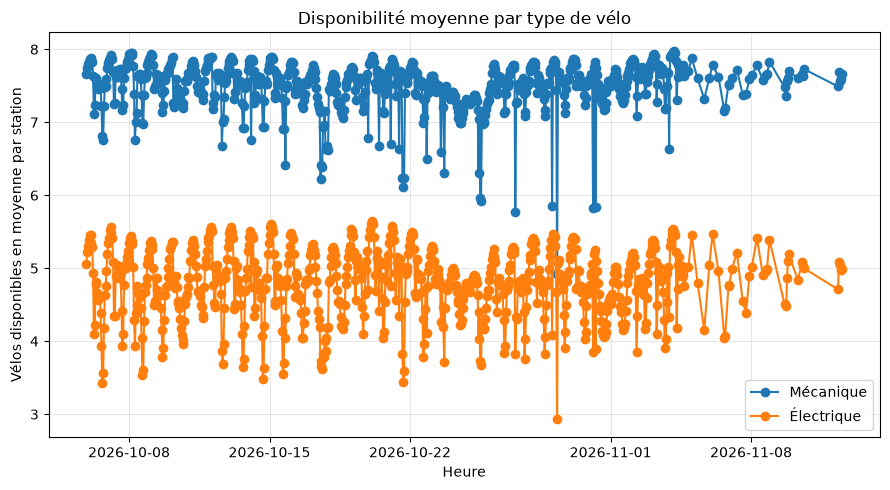

In [2]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df["heure"], df["avg_mecanique"], marker="o", label="Mécanique")
ax.plot(df["heure"], df["avg_electrique"], marker="o", label="Électrique")
ax.set_xlabel("Heure")
ax.set_ylabel("Vélos disponibles en moyenne par station")
ax.set_title("Disponibilité moyenne par type de vélo")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
part_moyenne = df["avg_mecanique"].sum() / (df["avg_mecanique"].sum() + df["avg_electrique"].sum())
print(f"Part moyenne de vélos mécaniques sur la période observée : {part_moyenne:.1%}")
print(f"Part moyenne de vélos électriques sur la période observée : {1 - part_moyenne:.1%}")

Part moyenne de vélos mécaniques sur la période observée : 61.0%
Part moyenne de vélos électriques sur la période observée : 39.0%


## Conclusion

Sur un mois complet, la part moyenne de vélos mécaniques disponibles est
de **61 %** contre **39 %** pour les électriques — stable par rapport à
la première estimation sur 2h30 (62 %/38 %), ce qui confirme que cette
proportion reflète bien la composition de la flotte plutôt qu'un artefact
de la fenêtre d'observation. Le graphique heure par heure montre que les
deux courbes suivent le même profil bimodal (creux aux heures de pointe)
observé au notebook 1, sans que l'un des deux types ne se vide
nettement plus vite que l'autre aux heures de pointe — une piste à
creuser plus finement par arrondissement en Phase 5.
